# Supplementary Figure S4a. Number of trans-eQTL versus number of phenotype PCs

For each ROSMAP expression context, the number of variants with a marginal trans-association p < 1e-6 for at least one gene (genome-wide marginal scan, `transQTL_calling/12_w_genoPC_Yres_X/summary.R`), after regressing 0, 1, 2, ... phenotype principal components together with biological and genotype-PC covariates out of the expression matrix. The red dashed line is the same count with no covariate adjustment at all (`transQTL_calling/13_simple_X_Y`). Counts are raw; no test or transformation is applied. Panel reproduces `Manu_Figures/Figure2.ipynb` cell 86.

Input: `data/Figure_S4a_trans_eqtl_vs_pheno_pcs.rds` (list: `adjusted`, `unadjusted`).

In [1]:
library(ggplot2)
d <- readRDS("data/Figure_S4a_trans_eqtl_vs_pheno_pcs.rds")
head(d$adjusted)
d$unadjusted

,context,n_pheno_pc,n_trans_eqtl
,<fct>,<int>,<int>
1,Mic,0,435
2,Mic,1,446
3,Mic,2,421
4,Mic,3,456
5,Mic,4,470
6,Mic,5,456


context,n_trans_eqtl
<fct>,<int>
Mic,443
Exc,434
Inh,579
Ast,607
Oli,679
OPC,438
DLPFC,465
AC,621
PCC,569


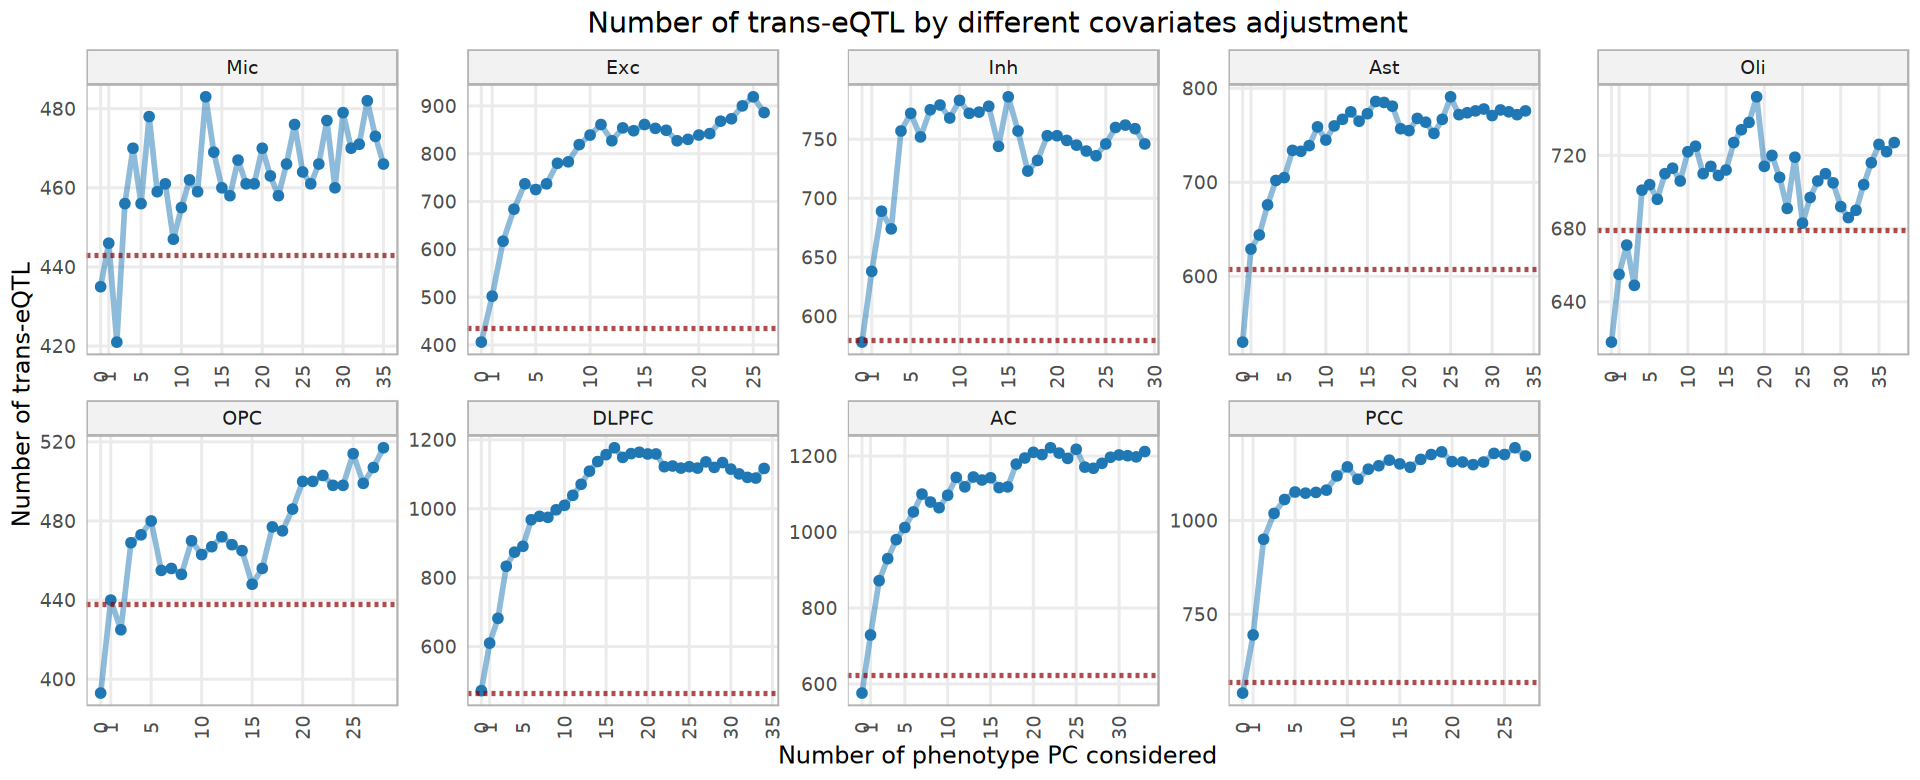

In [2]:
p <- ggplot(d$adjusted, aes(x = n_pheno_pc, y = n_trans_eqtl)) +
  geom_line(colour = "#1F78B4", linewidth = 1.2, alpha = 0.5) +
  geom_point(colour = "#1F78B4", size = 2) +
  geom_hline(data = d$unadjusted, aes(yintercept = n_trans_eqtl),
             colour = "darkred", linetype = "dashed", linewidth = 1.1, alpha = 0.7) +
  facet_wrap(~ context, scales = "free", ncol = 5) +
  scale_x_continuous(breaks = function(x) c(0, 1, seq(5, max(x, na.rm = TRUE), by = 5))) +
  labs(title = "Number of trans-eQTL by different covariates adjustment",
       x = "Number of phenotype PC considered", y = "Number of trans-eQTL") +
  theme_minimal(base_size = 14) +
  theme(panel.grid.minor = element_blank(),
        panel.border = element_rect(colour = "gray70", fill = NA, linewidth = 0.5),
        strip.background = element_rect(fill = "gray95", colour = "gray70"),
        axis.text.x = element_text(angle = 90, vjust = 0.5),
        plot.title = element_text(hjust = 0.5))
options(repr.plot.width = 16, repr.plot.height = 6.5)
p